# CREMA-D: exploratory data analysis

What the dataset contains, how it was recorded, what each of our five labels means, and why some labels are
missing for some clips. Everything here uses the files the experiments use: `clips.csv` (one row per clip, labels
frozen 18 Nov), `cremad.h5` (features) and the three frozen actor splits.

**Contents**
1. What a clip is
2. How the recordings were organised
3. Task 1: displayed emotion (and task 3: valence)
4. Task 4: displayed intensity, and why it is missing for most clips
5. Task 2: perceived emotion
6. Task 5: perceived intensity
7. The actors
8. Audio length
9. The actor splits
10. Missing labels and the loss-weight question
11. What a model has to beat

In [1]:
import json
import cv2, h5py, numpy as np, pandas as pd, soundfile as sf
import matplotlib.pyplot as plt
from mffer.config import load_paths
from mffer.data.cremad import EMOTIONS, AUDIOVISUAL_ROWS

paths = load_paths()
clips = pd.read_csv(paths.processed / "clips.csv")
NAMES = {"ANG": "Anger", "DIS": "Disgust", "FEA": "Fear", "HAP": "Happy", "NEU": "Neutral", "SAD": "Sad"}

# Chart style: thin bars, recessive axes, one blue for single series, blue/orange for two.
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (8, 3.2), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#bdbcb6", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#ecebe7", "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def bars(ax, labels, values, color=BLUE, fmt="{:,}", rotate=0):
    b = ax.bar(labels, values, color=color, width=0.6, edgecolor="white", linewidth=1.5)
    ax.bar_label(b, labels=[fmt.format(v) for v in values], padding=2, fontsize=9, color=MUTED)
    ax.tick_params(axis="x", rotation=rotate)
    return b

print(f"{len(clips):,} clips · {clips.actor_id.nunique()} actors · {clips.sentence.nunique()} sentences · 6 emotions")

7,442 clips · 91 actors · 12 sentences · 6 emotions


## 1. What a clip is

A **clip** is one actor saying one short sentence while acting one emotion, filmed and recorded at the same time
(about 2.5 s). Each clip has:

- **video** (480×360, 30 fps) and **audio** (16 kHz WAV);
- the **intended emotion**: what the actor was told to act (in the file name, e.g. `1001_ITS_HAP_XX` = actor 1001,
  sentence ITS, Happy, intensity unspecified);
- **ratings**: crowd-sourced raters watched and/or heard the clip and said which emotion they perceived and how
  strong it was (0–100).

Below, the same actor says the same sentence in all six emotions (the middle frame of our 10 sampled frames).

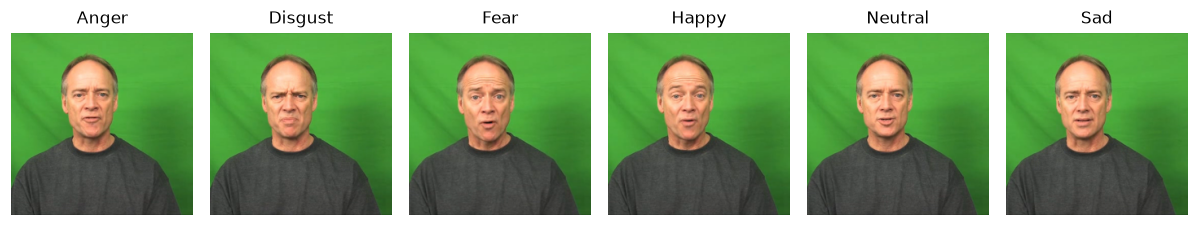

In [2]:
fig, axes = plt.subplots(1, 6, figsize=(11, 2.3))
with h5py.File(paths.processed / "cremad.h5") as h5:
    for ax, emotion in zip(axes, EMOTIONS):
        row = clips.index[(clips.actor_id == 1001) & (clips.sentence == "ITS") & (clips.displayed_emotion == emotion)][0]
        ax.imshow(h5["video"][row, 5]); ax.set_title(NAMES[emotion], loc="center", fontweight="normal"); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. How the recordings were organised

The dataset is a **grid**: every actor says each of 12 fixed sentences in each of the 6 emotions. One sentence,
*"It's eleven o'clock"* (IEO), was recorded more often: three times per emotion, at **low, medium and high**
intensity (Neutral has no intensity, so once). Every other sentence was recorded once per emotion with the
intensity left **unspecified** (`XX`).

So each actor has 11 sentences × 6 emotions = 66 clips, plus IEO: 5 emotions × 3 intensities + 1 Neutral = 16,
for **82 clips** (a few actors have 76–81 because some recordings were unusable).

In [3]:
per_actor = clips.groupby("actor_id").size()
print(f"clips per actor: min {per_actor.min()}, mean {per_actor.mean():.1f}, max {per_actor.max()}")

table = clips.pivot_table(index="sentence", columns="displayed_level", values="clip_id", aggfunc="count", fill_value=0)
table = table[["XX", "LO", "MD", "HI"]].sort_values("XX")
table["total"] = table.sum(axis=1)
table

clips per actor: min 76, mean 81.8, max 82


displayed_level,XX,LO,MD,HI,total
sentence,,,,,
IEO,91,455,455,455,1456
ITH,540,0,0,0,540
MTI,540,0,0,0,540
WSI,540,0,0,0,540
ITS,545,0,0,0,545
TIE,545,0,0,0,545
DFA,546,0,0,0,546
IOM,546,0,0,0,546
IWL,546,0,0,0,546


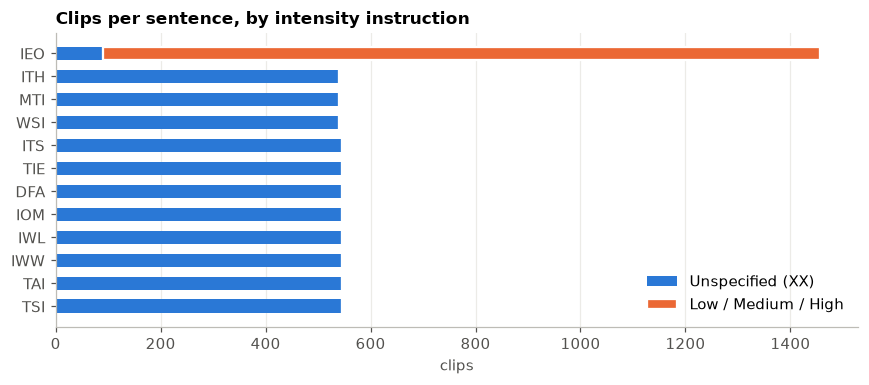

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
order = table.index[::-1]
ax.barh(order, table.loc[order, "XX"], color=BLUE, height=0.6, label="Unspecified (XX)")
ax.barh(order, table.loc[order, ["LO", "MD", "HI"]].sum(axis=1), left=table.loc[order, "XX"], color=ORANGE,
        height=0.6, label="Low / Medium / High", edgecolor="white", linewidth=1.5)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Clips per sentence, by intensity instruction"); ax.set_xlabel("clips")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

**Takeaway:** only the orange part, IEO at low/medium/high, carries an intensity instruction.
That matters for task 4 (section 4).

## 3. Task 1: displayed emotion (and task 3: displayed valence)

**Displayed emotion** = the emotion the actor was told to act. Because of the grid design it is almost perfectly
**balanced**: each emotion has 1/6 of the clips (Neutral slightly fewer, since it has no intensity versions).

**Displayed valence** is derived from it: Happy → positive, Neutral → neutral, the other four → negative.
So valence is **unbalanced**: two thirds of the clips are "negative". A model that always answers "negative"
already gets about 68%.

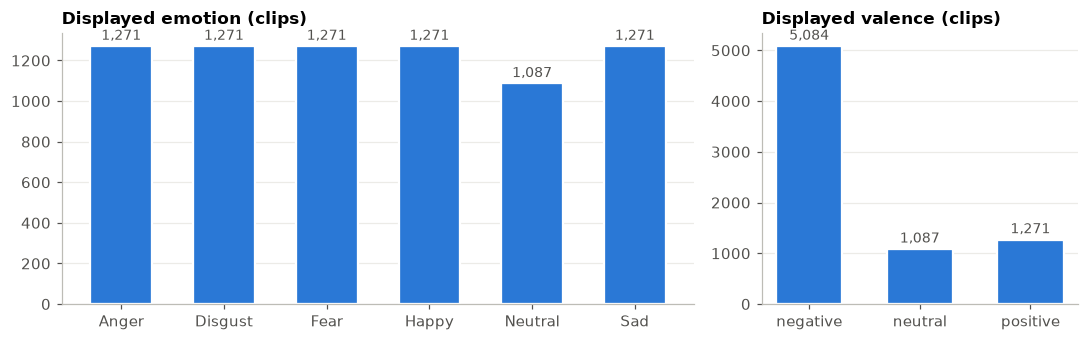

In [5]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={"width_ratios": [2, 1]})
counts = clips.displayed_emotion.value_counts()[EMOTIONS]
bars(a, [NAMES[e] for e in EMOTIONS], counts.values); a.set_title("Displayed emotion (clips)")
val = clips.displayed_valence.value_counts()[["negative", "neutral", "positive"]]
bars(b, val.index, val.values); b.set_title("Displayed valence (clips)")
plt.tight_layout(); plt.show()

## 4. Task 4: displayed intensity, and why it is missing for most clips

**Displayed intensity** = how strongly the actor was told to act. We turn the instruction into a number:
low = 1/3, medium = 2/3, high = 1.

But as section 2 showed, the instruction exists **only for IEO clips**. For 82% of clips it is `XX`, which means
*"nobody told the actor"*. It does **not** mean "medium". There is no correct answer for those clips.

The draft paper's approach (as far as we can tell) gave those clips a placeholder value. The model then scores
almost perfectly by always predicting the placeholder, which is why the draft's error looked so small. We instead
**mask** them: the model is trained and scored on this task **only on the 1,365 clips that have a real level**.
The other clips still count for the other four tasks.

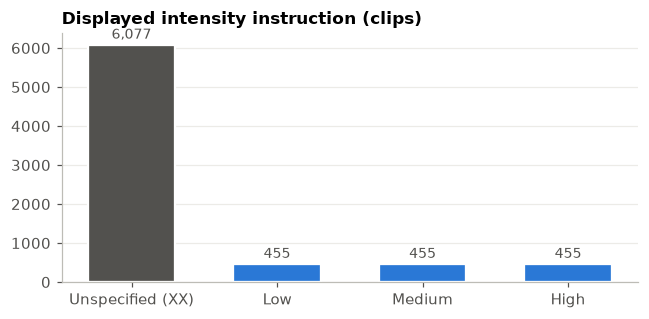

clips with a real displayed-intensity label: 1,365 of 7,442 (18.3%)


In [6]:
levels = clips.displayed_level.value_counts()[["XX", "LO", "MD", "HI"]]
fig, ax = plt.subplots(figsize=(6, 3))
bars(ax, ["Unspecified (XX)", "Low", "Medium", "High"], levels.values, color=[MUTED, BLUE, BLUE, BLUE])
ax.set_title("Displayed intensity instruction (clips)"); plt.tight_layout(); plt.show()
print(f"clips with a real displayed-intensity label: {clips.displayed_intensity.notna().sum():,} "
      f"of {len(clips):,} ({clips.displayed_intensity.notna().mean():.1%})")

## 5. Task 2: perceived emotion

**Perceived emotion** = what the **raters** thought the emotion was: the majority vote of the people who
watched and heard the clip (audio-visual ratings). Two things to notice:

1. **Raters often disagree with the actor.** The heatmap shows, for each intended emotion (row), what raters
   picked. The diagonal is agreement. Happy and Neutral are recognised almost always; **Sad is called Neutral
   about half the time**, and Fear is often read as Neutral or Sad. Neutral is the raters' fallback, so it is the
   most common perceived emotion even though it is the *least* common displayed one.
2. **Some clips have a tie**: e.g. 4 raters said Neutral and 4 said Sad (`N:S`). There is no single answer, so
   for this task those 420 clips (5.6%) are **masked**, exactly like the missing intensities above.

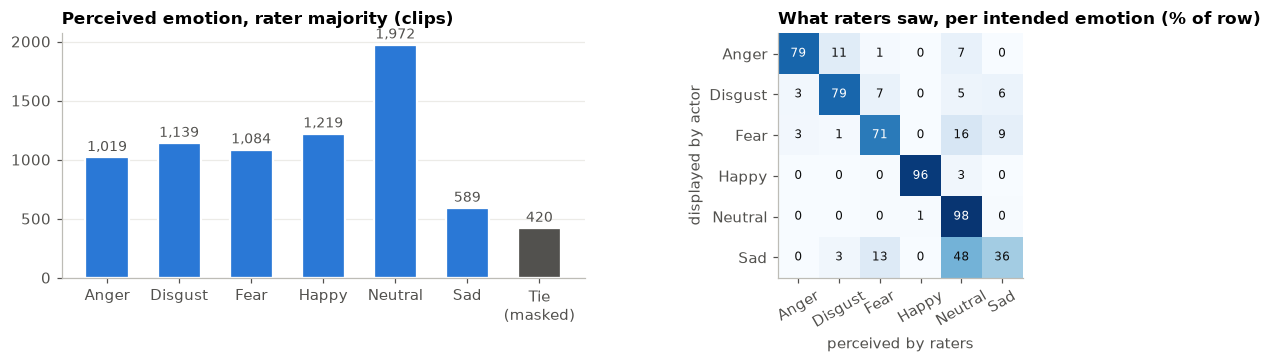

raters agree with the intended emotion on 76.5% of clips


In [7]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 1.1]})
pe = clips.perceived_emotion.fillna("TIE").value_counts().reindex(EMOTIONS + ["TIE"])
bars(a, [NAMES[e] for e in EMOTIONS] + ["Tie\n(masked)"], pe.values, color=[BLUE] * 6 + [MUTED])
a.set_title("Perceived emotion, rater majority (clips)")

rated = clips.dropna(subset=["perceived_emotion"])
conf = pd.crosstab(rated.displayed_emotion, rated.perceived_emotion, normalize="index").loc[EMOTIONS, EMOTIONS] * 100
im = b.imshow(conf.values, cmap="Blues", vmin=0, vmax=100)
b.set_xticks(range(6), [NAMES[e] for e in EMOTIONS], rotation=30); b.set_yticks(range(6), [NAMES[e] for e in EMOTIONS])
b.set_xlabel("perceived by raters"); b.set_ylabel("displayed by actor"); b.grid(False)
for i in range(6):
    for j in range(6):
        b.text(j, i, f"{conf.values[i, j]:.0f}", ha="center", va="center", fontsize=8,
               color="white" if conf.values[i, j] > 55 else "#0b0b0b")
b.set_title("What raters saw, per intended emotion (% of row)")
plt.tight_layout(); plt.show()
print(f"raters agree with the intended emotion on {(rated.displayed_emotion == rated.perceived_emotion).mean():.1%} of clips")

raters per clip (audio-visual): median 10, range 5–12


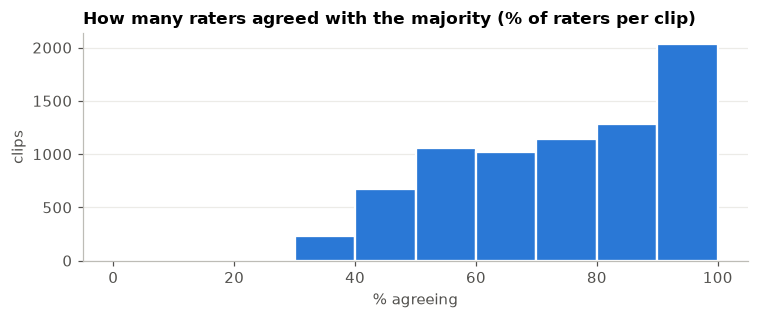

In [8]:
votes = pd.read_csv(paths.raw / "processedResults" / "tabulatedVotes.csv")
av = votes[votes.iloc[:, 0] >= AUDIOVISUAL_ROWS]
print(f"raters per clip (audio-visual): median {av.numResponses.median():.0f}, range {av.numResponses.min()}–{av.numResponses.max()}")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(av.agreement * 100, bins=np.arange(0, 101, 10), color=BLUE, edgecolor="white", linewidth=1.5)
ax.set_title("How many raters agreed with the majority (% of raters per clip)"); ax.set_xlabel("% agreeing"); ax.set_ylabel("clips")
plt.tight_layout(); plt.show()

**Takeaway:** perceived emotion is a noisier, harder target than displayed emotion. Even the crowd is split
on many clips, so a model will score lower here, and that is expected rather than a failure.

## 6. Task 5: perceived intensity

**Perceived intensity** = how strong the raters judged the emotion, averaged over all raters and divided by 100.
Every clip has it (ties included), so nothing is masked.

The values bunch tightly around 0.64. That makes the **"always guess the average"** baseline hard to beat on
mean absolute error (MAE): it is already off by only about 0.09. A model has to get below that to show it learned
anything about intensity. Section 11 gives the exact baseline on a test split.

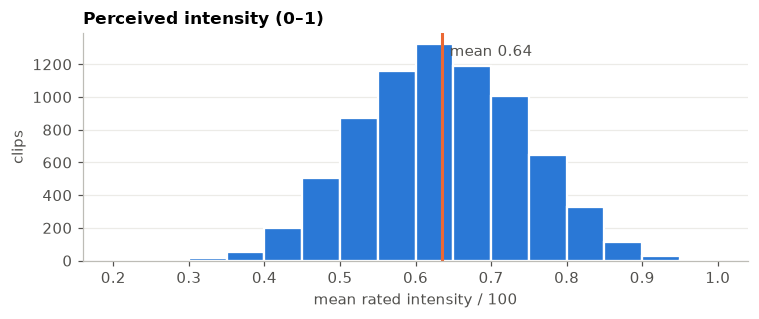

mean 0.635, sd 0.106, MAE of always guessing the mean: 0.086


In [9]:
pi = clips.perceived_intensity
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(pi, bins=np.arange(0.2, 1.01, 0.05), color=BLUE, edgecolor="white", linewidth=1.5)
ax.axvline(pi.mean(), color=ORANGE, linewidth=2); ax.text(pi.mean() + 0.01, ax.get_ylim()[1] * 0.9, f"mean {pi.mean():.2f}", color=MUTED)
ax.set_title("Perceived intensity (0–1)"); ax.set_xlabel("mean rated intensity / 100"); ax.set_ylabel("clips")
plt.tight_layout(); plt.show()
print(f"mean {pi.mean():.3f}, sd {pi.std():.3f}, MAE of always guessing the mean: {(pi - pi.mean()).abs().mean():.3f}")

## 7. The actors

91 actors (48 male, 43 female), aged 20 to 74. Age and sex are the **demographic** inputs of the model.
They are also why the splits are **stratified by sex**: every train/val/test part keeps roughly the same mix.

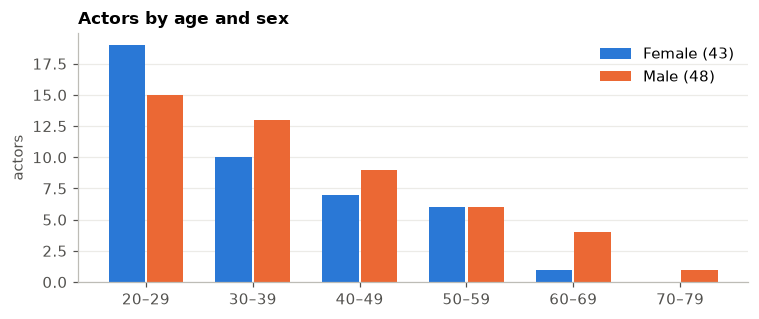

In [10]:
actors = clips.groupby("actor_id")[["age", "sex"]].first()
edges = np.arange(20, 81, 10)
f = np.histogram(actors.age[actors.sex == "Female"], edges)[0]; m = np.histogram(actors.age[actors.sex == "Male"], edges)[0]
x = np.arange(len(edges) - 1)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(x - 0.18, f, 0.34, color=BLUE, label=f"Female ({(actors.sex == 'Female').sum()})")
ax.bar(x + 0.18, m, 0.34, color=ORANGE, label=f"Male ({(actors.sex == 'Male').sum()})")
ax.set_xticks(x, [f"{a}–{a + 9}" for a in edges[:-1]]); ax.set_ylabel("actors"); ax.legend(frameon=False)
ax.set_title("Actors by age and sex"); plt.tight_layout(); plt.show()

## 8. Audio length

Clips last 1.3–5 s (median 2.5 s). The audio input is a fixed grid of 100 MFCC frames of 40 ms = **4 s**; shorter
clips are padded with zeros, and the ~1% of clips longer than 4 s lose their last part.

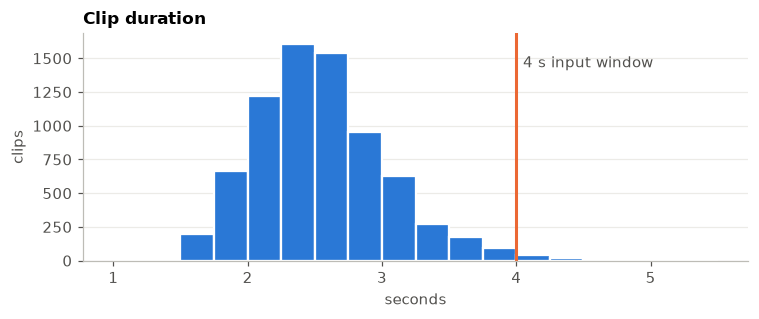

median 2.50 s; 84 clips (1.1%) longer than 4 s


In [11]:
seconds = np.array([sf.info(paths.raw / "AudioWAV" / f"{c}.wav").duration for c in clips.clip_id])
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(seconds, bins=np.arange(1, 5.51, 0.25), color=BLUE, edgecolor="white", linewidth=1.5)
ax.axvline(4, color=ORANGE, linewidth=2); ax.text(4.05, ax.get_ylim()[1] * 0.85, "4 s input window", color=MUTED)
ax.set_title("Clip duration"); ax.set_xlabel("seconds"); ax.set_ylabel("clips"); plt.tight_layout(); plt.show()
print(f"median {np.median(seconds):.2f} s; {(seconds > 4).sum()} clips ({(seconds > 4).mean():.1%}) longer than 4 s")

## 9. The actor splits

**Why split by actor:** if the same person appears in training and test, the model can recognise the *person*
(face, voice) instead of the *emotion*, and the test score looks too good. The draft's 95.9% likely came partly
from that. Here, train, validation and test actors never overlap, so test measures performance on
**people the model has never seen**, which is what a kiosk meets.

There are three different splits (seeds 0, 1, 2), so every core result can be reported as mean ± sd.

In [12]:
rows = []
for k in range(3):
    split = json.loads((paths.splits / f"split_{k}.json").read_text())
    for part in ("train", "val", "test"):
        ids = split[part]
        rows.append({"split": k, "part": part, "actors": len(ids), "female": int((actors.loc[ids, "sex"] == "Female").sum()),
                     "clips": int(clips.actor_id.isin(ids).sum())})
        assert not set(ids) & set(sum((split[p] for p in ("train", "val", "test") if p != part), []))
pd.DataFrame(rows).pivot(index="part", columns="split", values=["actors", "female", "clips"]).loc[["train", "val", "test"]]

actors         female         clips            
split      0   1   2      0   1   2     0     1     2
part                                                 
train     63  63  63     30  30  30  5152  5147  5158
val        9   9   9      4   4   4   738   738   738
test      19  19  19      9   9   9  1552  1557  1546

## 10. Missing labels and the loss-weight question

Not every clip has every label:

| Task | Clips with a label | Why the rest are missing |
|---|---|---|
| displayed emotion | all | — |
| perceived emotion | 94% | rater tie |
| displayed valence | all | — |
| displayed intensity | 18% | only IEO was recorded at a set intensity |
| perceived intensity | all | — |

During training the model sees a batch of 16 clips and gets a "mistake score" (loss) per task. A missing label is
given **weight 0**, so it is simply skipped. That part is correct.

**The catch.** Keras then divides each task's total mistakes by **16**, the whole batch, not by the number of
clips that actually had that label. In a typical batch only about 3 clips have a displayed-intensity label, so that
task's score is divided by 16 instead of 3 and looks about **5× smaller** than it is. The model then pays about
5× less attention to it than the weight we chose. The table computes the effective weight:
**chosen weight × share of clips that have the label.**

In [13]:
n = len(clips)
present = {"displayed emotion": n, "perceived emotion": clips.perceived_emotion.notna().sum(), "displayed valence": n,
           "displayed intensity": clips.displayed_intensity.notna().sum(), "perceived intensity": n}
weights = {"displayed emotion": 1.0, "perceived emotion": 1.0, "displayed valence": 1.0,
           "displayed intensity": 0.2, "perceived intensity": 0.2}
masks = pd.DataFrame({"clips with label": present, "share": {k: v / n for k, v in present.items()}, "chosen weight": weights})
masks["effective weight (a: leave it)"] = masks["chosen weight"] * masks["share"]
masks["weight to set (b: compensate)"] = masks["chosen weight"] / masks["share"]
masks.style.format({"share": "{:.1%}", "chosen weight": "{:.2f}", "effective weight (a: leave it)": "{:.3f}",
                    "weight to set (b: compensate)": "{:.2f}", "clips with label": "{:,}"})

,clips with label,share,chosen weight,effective weight (a: leave it),weight to set (b: compensate)
displayed emotion,"7,442",100.0%,1.00,1.000,1.00
perceived emotion,"7,022",94.4%,1.00,0.944,1.06
displayed valence,"7,442",100.0%,1.00,1.000,1.00
displayed intensity,"1,365",18.3%,0.20,0.037,1.09
perceived intensity,"7,442",100.0%,0.20,0.200,0.20


**The two options (decision 2 in `docs/pipeline-design.md`):**

- **(a) leave it.** Displayed intensity effectively trains with weight ≈ 0.04 instead of 0.2; perceived emotion
  with ≈ 0.94 instead of 1.0. Report the effective weights in the paper.
- **(b) compensate.** Set displayed intensity to ≈ 1.09 and perceived emotion to ≈ 1.06 internally, so each task
  gets the attention its chosen weight says. Report the chosen weights and one sentence on the correction.

Recommendation: **(b)**. Since the paper tests all five draft tasks, displayed intensity should actually be learned,
not quietly shrunk to almost nothing.

## 11. What a model has to beat

The simplest possible "models", fit on the split-0 training actors and scored on its test actors:
for classification, always answer the most common training class; for intensities, always answer the training
average. Any real result in the paper should be read against these numbers.

In [14]:
split0 = json.loads((paths.splits / "split_0.json").read_text())
train, test = clips[clips.actor_id.isin(split0["train"])], clips[clips.actor_id.isin(split0["test"])]
rows = []
for task in ("displayed_emotion", "perceived_emotion", "displayed_valence"):
    guess = train[task].mode()[0]; scored = test[task].dropna()
    rows.append({"task": task.replace("_", " "), "always guess": NAMES.get(guess, guess),
                 "score": f"accuracy {(scored == guess).mean():.1%}"})
for task in ("displayed_intensity", "perceived_intensity"):
    guess = train[task].mean(); scored = test[task].dropna()
    rows.append({"task": task.replace("_", " "), "always guess": f"{guess:.3f}", "score": f"MAE {(scored - guess).abs().mean():.3f}"})
pd.DataFrame(rows).set_index("task")

,always guess,score
task,,
displayed emotion,Anger,accuracy 17.1%
perceived emotion,Neutral,accuracy 26.3%
displayed valence,negative,accuracy 68.3%
displayed intensity,0.667,MAE 0.222
perceived intensity,0.631,MAE 0.090


## Summary

- 7,442 clips, 91 actors, 12 sentences, 6 emotions; a balanced **grid**, so displayed emotion is balanced (chance ≈ 17%).
- **Valence** is two-thirds negative: a trivial model already gets ~68%.
- **Displayed intensity** only exists for one sentence (18% of clips); the rest are masked.
- **Perceived emotion** disagrees with the intended emotion on about a quarter of clips, is Neutral-heavy, and has
  420 ties (masked). It is the hardest task by nature.
- **Perceived intensity** is tightly bunched, so the "guess the average" baseline is strong.
- **Splits by actor** make the test set contain only unseen people.